# 🎯 STAGE 1: FANAR-9B Baseline on **ArabLegalEval** Dataset

## Research: Arabic Legal LLM Compression - Paper 2 (NeurIPS/ICLR Target)

### Dataset: ArabLegalEval (THIQAH + KAUST)
- **Source:** https://github.com/Thiqah/ArabLegalEval
- **Paper:** https://arxiv.org/pdf/2408.07983
- **Tasks:** MCQ + QA (Saudi legal regulations)
- **Credibility:** ⭐⭐⭐⭐⭐ Peer-reviewed at ArabicNLP 2024

### Goal: Create the strongest teacher model on ArabLegalEval

**Experiments:**
- **Exp A:** Base model (no training) - Baseline
- **Exp B:** CPT only (continual pre-training)
- **Exp C:** SFT only (supervised fine-tuning)
- **Exp D:** CPT → SFT (sequential)

**Model:** FANAR-1-9B-Instruct (QCRI/Fanar-1-9B-Instruct)

## 📦 CELL 1: Install Dependencies

In [ ]:
# Install required packages
!pip install -q torch transformers accelerate bitsandbytes
!pip install -q peft datasets trl
!pip install -q sentencepiece protobuf
!pip install -q rouge-score nltk sacrebleu bert-score
!pip install -q pyarabic ftfy tqdm
!pip install -q matplotlib seaborn pandas

print("✅ Dependencies installed")

## 📥 CELL 2: Download ArabLegalEval Dataset

In [3]:
import os
import subprocess

# Clone the ArabLegalEval repository
if not os.path.exists('ArabLegalEval'):
    print("📥 Cloning ArabLegalEval repository...")
    !git https://github.com/Thiqah/ArabLegalEval.git
    print("✅ Repository cloned")
else:
    print("✅ Repository already exists")

# List contents
print("\n📁 Repository structure:")
!ls -la ArabLegalEval/

print("\n📂 Looking for data files:")
!find ArabLegalEval/ -name "*.json" -o -name "*.jsonl" -o -name "*.csv" -o -name "*.parquet" 2>/dev/null | head -30

✅ Repository already exists

📁 Repository structure:
total 23
drwxr-sr-x 7 pmp6991 p32887  4096 May  2 09:11 .
drwxr-sr-x 7 pmp6991 p32887  4096 May  6 13:29 ..
drwxr-sr-x 5 pmp6991 p32887  4096 May  2 09:12 benchmarkArLegalBench
drwxr-sr-x 3 pmp6991 p32887  4096 May  2 09:11 benchmarkMCQs
drwxr-sr-x 5 pmp6991 p32887  4096 May  2 09:11 benchmarkQA
drwxr-sr-x 5 pmp6991 p32887  4096 May  2 09:11 data
-rw-r--r-- 1 pmp6991 p32887   146 May  2 09:11 .dvcignore
drwxr-sr-x 7 pmp6991 p32887  4096 May  2 09:11 .git
-rw-r--r-- 1 pmp6991 p32887  3212 May  2 09:11 .gitignore
-rw-r--r-- 1 pmp6991 p32887 13974 May  2 09:11 llm_config.yaml
-rw-r--r-- 1 pmp6991 p32887  3291 May  2 09:11 .pre-commit-config.yaml
-rw-r--r-- 1 pmp6991 p32887  2176 May  2 09:11 README.md
-rw-r--r-- 1 pmp6991 p32887  1170 May  2 09:11 requirements.txt
-rw-r--r-- 1 pmp6991 p32887   453 May  2 09:11 run_all.sh

📂 Looking for data files:
ArabLegalEval/benchmarkQA/Najiz_QA_with_context_v2.benchmark.json
ArabLegalEval/benchmarkQ

## 📚 CELL 3: Import Libraries

In [1]:
import json
import re
import gc
import time
import random
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from typing import List, Dict, Tuple, Optional
from collections import Counter, defaultdict
from datetime import datetime

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
    BitsAndBytesConfig,
)

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
    PeftModel,
    TaskType
)

from datasets import Dataset as HFDataset
from rouge_score import rouge_scorer
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Set random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"✅ PyTorch version: {torch.__version__}")
print(f"✅ CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"✅ GPU: {torch.cuda.get_device_name(0)}")
    print(f"✅ GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

/miniconda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ PyTorch version: 2.9.0+cu128
✅ CUDA available: True
✅ GPU: NVIDIA A100-PCIE-40GB
✅ GPU Memory: 42.41 GB


## ⚙️ CELL 4: Configuration

In [4]:
class Config:
    """Configuration for ArabLegalEval Stage 1 experiments"""
    
    # Model
    MODEL_NAME = "QCRI/Fanar-1-9B-Instruct"
    
    # ArabLegalEval paths (will detect automatically in Cell 5)
    ARABLEGAL_DIR = "./ArabLegalEval"
    
    # Output directories
    OUTPUT_DIR = "./outputs_arablegal"
    RESULTS_DIR = "./results_arablegal"
    MODELS_DIR = "./models_arablegal"
    
    # Train/Eval split
    EVAL_RATIO = 0.2
    
    # LoRA Configuration
    LORA_R = 16
    LORA_ALPHA = 32
    LORA_DROPOUT = 0.05
    LORA_TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj",
                            "gate_proj", "up_proj", "down_proj"]
    
    # Training
    NUM_EPOCHS = 3
    BATCH_SIZE = 4
    GRADIENT_ACCUMULATION = 4
    LEARNING_RATE = 2e-4
    WARMUP_RATIO = 0.1
    MAX_LENGTH = 1024
    
    # Quantization
    USE_4BIT = True
    
    # Generation
    MAX_NEW_TOKENS = 256
    TEMPERATURE = 0.1
    TOP_P = 0.9
    
    SEED = 42

# Create directories
for dir_path in [Config.OUTPUT_DIR, Config.RESULTS_DIR, Config.MODELS_DIR]:
    os.makedirs(dir_path, exist_ok=True)

print("✅ Configuration set")
print(f"   Model: {Config.MODEL_NAME}")
print(f"   Dataset: ArabLegalEval")
print(f"   Results dir: {Config.RESULTS_DIR}")

✅ Configuration set
   Model: QCRI/Fanar-1-9B-Instruct
   Dataset: ArabLegalEval
   Results dir: ./results_arablegal


## 🔍 CELL 5: Explore ArabLegalEval Dataset Structure

In [6]:
# Find all data files in ArabLegalEval
def find_data_files(base_dir):
    """Find all JSON, JSONL, CSV, and Parquet files"""
    data_files = []
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file.endswith(('.json', '.jsonl', '.csv', '.parquet', '.tsv')):
                full_path = os.path.join(root, file)
                size = os.path.getsize(full_path)
                data_files.append({
                    'path': full_path,
                    'name': file,
                    'size_kb': size / 1024,
                    'dir': root
                })
    return data_files

data_files = find_data_files(Config.ARABLEGAL_DIR)

print(f"📁 Found {len(data_files)} data files:\n")
for f in data_files:
    print(f"   📄 {f['name']:<50} {f['size_kb']:>8.1f} KB  | {f['dir']}")

# Look for MCQ and QA specifically
print("\n🔍 MCQ-related files:")
for f in data_files:
    if 'mcq' in f['name'].lower() or 'mcq' in f['dir'].lower():
        print(f"   ✓ {f['path']}")

print("\n🔍 QA-related files:")
for f in data_files:
    if ('qa' in f['name'].lower() or 'qa' in f['dir'].lower()) and 'mcq' not in f['name'].lower():
        print(f"   ✓ {f['path']}")

📁 Found 32 data files:

   📄 Najiz_QA_with_context_v2.benchmark.json               100.2 KB  | ./ArabLegalEval/benchmarkQA
   📄 qa_results.csv                                       2709.2 KB  | ./ArabLegalEval/benchmarkQA
   📄 benchmark_filtered_najiz_faq_v0_0.json               1657.2 KB  | ./ArabLegalEval/benchmarkQA/eval_questions
   📄 direct_qa.benchmark.json                               51.0 KB  | ./ArabLegalEval/benchmarkQA/eval_questions
   📄 QA_to_MCQs_COT_Samples.benchmark.json                  61.7 KB  | ./ArabLegalEval/benchmarkQA/eval_questions
   📄 benchmark.json                                         36.6 KB  | ./ArabLegalEval/benchmarkQA/eval_questions
   📄 Five_Shot_MCQs_Samples.json                            58.0 KB  | ./ArabLegalEval/benchmarkQA/eval_questions/MCQs_samples_02
   📄 Three_Shot_MCQs_Samples.json                           58.7 KB  | ./ArabLegalEval/benchmarkQA/eval_questions/MCQs_samples_02
   📄 QA_to_MCQs_COT_Samples.json                            91

## 📊 CELL 6: Load ArabLegalEval Dataset

In [7]:
def load_file(filepath):
    """Load a data file based on its extension"""
    ext = filepath.split('.')[-1].lower()
    
    try:
        if ext == 'json':
            with open(filepath, 'r', encoding='utf-8') as f:
                return json.load(f)
        elif ext == 'jsonl':
            data = []
            with open(filepath, 'r', encoding='utf-8') as f:
                for line in f:
                    data.append(json.loads(line))
            return data
        elif ext == 'csv':
            return pd.read_csv(filepath).to_dict('records')
        elif ext == 'tsv':
            return pd.read_csv(filepath, sep='\t').to_dict('records')
        elif ext == 'parquet':
            return pd.read_parquet(filepath).to_dict('records')
    except Exception as e:
        print(f"❌ Error loading {filepath}: {e}")
        return None
    return None

# Try loading each data file and show its structure
print("📂 LOADING DATA FILES TO EXAMINE STRUCTURE:\n")
print("="*80)

for f in data_files[:10]:  # Limit to first 10
    print(f"\n📄 File: {f['name']}")
    print(f"   Path: {f['path']}")
    
    data = load_file(f['path'])
    
    if data is None:
        print("   ⚠️  Could not load")
        continue
    
    if isinstance(data, list):
        print(f"   📊 Items: {len(data)}")
        if data:
            print(f"   📋 First item keys: {list(data[0].keys()) if isinstance(data[0], dict) else 'Not a dict'}")
            if isinstance(data[0], dict):
                # Show first item briefly
                for k, v in list(data[0].items())[:5]:
                    val_str = str(v)[:80]
                    print(f"      {k}: {val_str}")
    elif isinstance(data, dict):
        print(f"   📋 Top-level keys: {list(data.keys())}")
    
    print("-"*80)

📂 LOADING DATA FILES TO EXAMINE STRUCTURE:


📄 File: Najiz_QA_with_context_v2.benchmark.json
   Path: ./ArabLegalEval/benchmarkQA/Najiz_QA_with_context_v2.benchmark.json
   📋 Top-level keys: ['questions', 'ground_truths', 'context']
--------------------------------------------------------------------------------

📄 File: qa_results.csv
   Path: ./ArabLegalEval/benchmarkQA/qa_results.csv
   📊 Items: 1106
   📋 First item keys: ['question', 'ground_truth', 'question_i', 'llm', 'context', 'llm_answer', 'answer_similarity', 'questions', 'ground_truths', 'context_r', 'Experiment']
      question: على من ترفع الدعوى الجزائية الخاصة؟
      ground_truth: ترفع دعوى الحق الخاص على المتهم إذا كان أهلًا، وعلى الولي أو الوصي إذا كان المته
      question_i: 0
      llm: GroundTruthLLM
      context: ترفع دعوى الحق الخاص على المتهم إذا كان أهلًا، وعلى الولي أو الوصي إذا كان المته
--------------------------------------------------------------------------------

📄 File: benchmark_filtered_najiz_faq_v0_0

## 🎯 CELL 7: Identify and Load MCQ + QA Tasks

In [7]:
# ArabLegalEval has 3 main parent tasks:
# 1. Saudi Legal MCQs
# 2. QA pairs (with relevant Saudi regulations in question)
# 3. Translated LegalBench tasks

# Common locations to check
mcq_candidates = []
qa_candidates = []

for f in data_files:
    name_lower = f['name'].lower()
    dir_lower = f['dir'].lower()
    
    # MCQ candidates
    if 'mcq' in name_lower or 'mcq' in dir_lower or 'multiple_choice' in name_lower:
        mcq_candidates.append(f)
    
    # QA candidates (excluding MCQ)
    elif ('qa' in name_lower or 'qa' in dir_lower or 'question' in name_lower) and 'mcq' not in name_lower:
        qa_candidates.append(f)

print("🎯 MCQ Candidate Files:")
for f in mcq_candidates:
    print(f"   📄 {f['path']}")

print("\n🎯 QA Candidate Files:")
for f in qa_candidates:
    print(f"   📄 {f['path']}")

# Also try HuggingFace datasets if available
print("\n💡 Alternative: Try loading from HuggingFace if local fails:")
print("   from datasets import load_dataset")
print("   data = load_dataset('Thiqah/ArabLegalEval')")

NameError: name 'data_files' is not defined

In [9]:
# Load and normalize MCQ data
def normalize_mcq_item(item):
    """
    Normalize MCQ item to consistent format.
    Handle different possible formats from ArabLegalEval.
    """
    # Possible question fields
    question = (
        item.get('question') or 
        item.get('Question') or 
        item.get('input') or
        item.get('text') or ''
    )
    
    # Possible options fields
    options = item.get('options') or item.get('choices') or {}
    
    # If options is a list, convert to dict
    if isinstance(options, list):
        if len(options) >= 4:
            options = {
                'A': options[0],
                'B': options[1],
                'C': options[2],
                'D': options[3]
            }
    
    # Possible answer fields
    correct_answer = (
        item.get('correct_answer') or
        item.get('answer') or
        item.get('label') or
        item.get('correct') or ''
    )
    
    # Normalize answer to letter
    if isinstance(correct_answer, int):
        # Convert index to letter (0->A, 1->B, etc.)
        correct_answer = chr(65 + correct_answer)
    elif isinstance(correct_answer, str):
        correct_answer = correct_answer.strip().upper()[:1] if correct_answer else ''
    
    return {
        'question': question,
        'options': options,
        'correct_answer': correct_answer,
        'explanation': item.get('explanation') or item.get('answer_explanation', ''),
        'context': item.get('context') or item.get('source') or item.get('regulation', ''),
        'task_type': item.get('task_type') or item.get('subject', 'general'),
        'original': item  # Keep original for reference
    }

def normalize_qa_item(item):
    """Normalize QA item to consistent format"""
    question = (
        item.get('question') or 
        item.get('Question') or 
        item.get('input') or
        item.get('text') or ''
    )
    
    answer = (
        item.get('answer') or
        item.get('correct_answer') or
        item.get('output') or
        item.get('response') or ''
    )
    
    return {
        'question': question,
        'answer': answer,
        'context': item.get('context') or item.get('regulation', ''),
        'explanation': item.get('explanation') or item.get('answer_explanation', ''),
        'task_type': item.get('task_type') or item.get('subject', 'general'),
        'original': item
    }

# Load MCQ data
all_mcq = []
for f in mcq_candidates:
    print(f"📥 Loading MCQ from: {f['name']}")
    data = load_file(f['path'])
    
    if data and isinstance(data, list):
        for item in data:
            if isinstance(item, dict):
                normalized = normalize_mcq_item(item)
                if normalized['question'] and normalized['options'] and normalized['correct_answer']:
                    all_mcq.append(normalized)
        print(f"   ✓ Loaded {len(data)} items")
    elif data and isinstance(data, dict):
        # Sometimes data is nested
        for key in ['data', 'examples', 'questions', 'items']:
            if key in data and isinstance(data[key], list):
                for item in data[key]:
                    normalized = normalize_mcq_item(item)
                    if normalized['question'] and normalized['options'] and normalized['correct_answer']:
                        all_mcq.append(normalized)
                break

print(f"\n✅ Total MCQ loaded: {len(all_mcq)}")

# Load QA data
all_qa = []
for f in qa_candidates:
    print(f"📥 Loading QA from: {f['name']}")
    data = load_file(f['path'])
    
    if data and isinstance(data, list):
        for item in data:
            if isinstance(item, dict):
                normalized = normalize_qa_item(item)
                if normalized['question'] and normalized['answer']:
                    all_qa.append(normalized)
        print(f"   ✓ Loaded {len(data)} items")
    elif data and isinstance(data, dict):
        for key in ['data', 'examples', 'questions', 'items']:
            if key in data and isinstance(data[key], list):
                for item in data[key]:
                    normalized = normalize_qa_item(item)
                    if normalized['question'] and normalized['answer']:
                        all_qa.append(normalized)
                break

print(f"\n✅ Total QA loaded: {len(all_qa)}")

# Show samples
if all_mcq:
    print("\n📝 Sample MCQ:")
    sample = all_mcq[0]
    print(f"   Question: {sample['question'][:200]}")
    print(f"   Options: {sample['options']}")
    print(f"   Correct: {sample['correct_answer']}")

if all_qa:
    print("\n📝 Sample QA:")
    sample = all_qa[0]
    print(f"   Question: {sample['question'][:200]}")
    print(f"   Answer: {sample['answer'][:200]}")

📥 Loading MCQ from: QA_to_MCQs_COT_Samples.benchmark.json


AttributeError: 'str' object has no attribute 'get'

## 🔧 CELL 9: Manual Data Loading (If Auto-Detection Failed)

**If the above cells didn't load data properly, modify the paths below to point to your specific files.**

In [10]:
# CORRECT LOADING CODE FOR ARABLEGAL EVAL
# Based on actual repository structure

import json
import pandas as pd
from collections import defaultdict

# ============================================================================
# LOAD MCQ DATA from CSV
# ============================================================================

MCQ_FILE = "./ArabLegalEval/data/benchmarkMCQs/MCQs.csv"

print(f"📥 Loading MCQ from: {MCQ_FILE}")
mcq_df = pd.read_csv(MCQ_FILE)

print(f"\n📊 MCQ DataFrame:")
print(f"   Shape: {mcq_df.shape}")
print(f"   Columns: {list(mcq_df.columns)}")
print(f"\n📋 First row:")
print(mcq_df.iloc[0])

📥 Loading MCQ from: ./ArabLegalEval/data/benchmarkMCQs/MCQs.csv

📊 MCQ DataFrame:
   Shape: (10564, 8)
   Columns: ['Context', 'Question', 'Correct Answer', 'Option 1', 'Option 2', 'Option 3', 'Option 4', 'Answer Key']

📋 First row:
Context           يودع الأمين لدى سجل الإفلاس حكم المحكمة بافتتا...
Question          متى يجب على الأمين أن يودع حكم المحكمة بافتتاح...
Correct Answer               خلال خمسة أيام من تاريخ افتتاح الإجراء
Option 1                    خلال ثلاثة أيام من تاريخ افتتاح الإجراء
Option 2                     خلال خمسة أيام من تاريخ افتتاح الإجراء
Option 3                     خلال عشرة أيام من تاريخ افتتاح الإجراء
Option 4                     خلال سبعة أيام من تاريخ افتتاح الإجراء
Answer Key                                                        1
Name: 0, dtype: object


In [27]:
import pandas as pd

MCQ_FILE = "./ArabLegalEval/data/benchmarkMCQs/MCQs.csv"

# Load and inspect
mcq_df = pd.read_csv(MCQ_FILE)

print("="*70)
print("📊 MCQ CSV INSPECTION")
print("="*70)
print(f"\n📐 Shape: {mcq_df.shape}")
print(f"📋 Total rows: {len(mcq_df)}")

print(f"\n📑 ALL COLUMNS:")
for i, col in enumerate(mcq_df.columns):
    # Get sample value
    sample_val = str(mcq_df[col].iloc[0])[:80] if len(mcq_df) > 0 else ''
    print(f"   {i+1}. '{col}'")
    print(f"      Sample: {sample_val}")
    print()

print("\n" + "="*70)
print("📝 FIRST 3 COMPLETE ROWS:")
print("="*70)
for idx in range(min(3, len(mcq_df))):
    print(f"\n--- ROW {idx+1} ---")
    for col in mcq_df.columns:
        val = str(mcq_df[col].iloc[idx])[:200]
        print(f"  {col}: {val}")
    print("-"*70)

📊 MCQ CSV INSPECTION

📐 Shape: (10564, 8)
📋 Total rows: 10564

📑 ALL COLUMNS:
   1. 'Context'
      Sample: يودع الأمين لدى سجل الإفلاس حكم المحكمة بافتتاح إجراء إعادة التنظيم المالي لصغار

   2. 'Question'
      Sample: متى يجب على الأمين أن يودع حكم المحكمة بافتتاح إجراء إعادة التنظيم المالي لصغار 

   3. 'Correct Answer'
      Sample: خلال خمسة أيام من تاريخ افتتاح الإجراء

   4. 'Option 1'
      Sample: خلال ثلاثة أيام من تاريخ افتتاح الإجراء

   5. 'Option 2'
      Sample: خلال خمسة أيام من تاريخ افتتاح الإجراء

   6. 'Option 3'
      Sample: خلال عشرة أيام من تاريخ افتتاح الإجراء

   7. 'Option 4'
      Sample: خلال سبعة أيام من تاريخ افتتاح الإجراء

   8. 'Answer Key'
      Sample: 1


📝 FIRST 3 COMPLETE ROWS:

--- ROW 1 ---
  Context: يودع الأمين لدى سجل الإفلاس حكم المحكمة بافتتاح إجراء إعادة التنظيم المالي لصغار المدينين أو قرارها بقبول الإيداع القضائي، وذلك خلال (خمسة) أيام من تاريخ افتتاح الإجراء.
  Question: متى يجب على الأمين أن يودع حكم المحكمة بافتتاح إجراء إعادة التنظي

In [23]:
import pandas as pd
import random

MCQ_FILE = "./ArabLegalEval/data/benchmarkMCQs/MCQs.csv"
mcq_df = pd.read_csv(MCQ_FILE)

print(f"📊 Loading {len(mcq_df)} rows...")

all_mcq = []
skipped = 0

for idx, row in mcq_df.iterrows():
    try:
        question = str(row['Question']).strip()
        
        opt1 = str(row['Option 1']).strip()
        opt2 = str(row['Option 2']).strip()
        opt3 = str(row['Option 3']).strip()
        opt4 = str(row['Option 4']).strip()
        
        # Answer Key is 0-indexed (0-3)
        answer_key = int(row['Answer Key'])
        
        if answer_key < 0 or answer_key > 3:
            skipped += 1
            continue
        
        # Map 0→A, 1→B, 2→C, 3→D
        correct_letter = chr(65 + answer_key)
        
        item = {
            'question': question,
            'options': {
                'A': opt1,
                'B': opt2,
                'C': opt3,
                'D': opt4
            },
            'correct_answer': correct_letter,
            'context': str(row['Context']).strip(),
            'correct_text': str(row['Correct Answer']).strip(),
            'explanation': '',
            'task_type': 'saudi_legal_mcq'
        }
        
        all_mcq.append(item)
        
    except Exception as e:
        skipped += 1
        continue

print(f"\n✅ Loaded {len(all_mcq)} MCQ items")
print(f"⚠️  Skipped: {skipped}")

📊 Loading 10564 rows...

✅ Loaded 10564 MCQ items
⚠️  Skipped: 0


In [29]:
import os
import json
from pathlib import Path

# Search for ALL JSON files that might have QA data
print("🔍 Searching for QA files...\n")

qa_candidates = [
    './ArabLegalEval/benchmarkQA/Najiz_QA_with_context_v2.benchmark.json',
    './ArabLegalEval/benchmarkQA/eval_questions/direct_qa.benchmark.json',
    './ArabLegalEval/benchmarkQA/eval_questions/benchmark_filtered_najiz_faq_v0_0.json',
    './ArabLegalEval/benchmarkQA/eval_questions/QA_to_MCQs_COT_Samples.benchmark.json',
    './ArabLegalEval/benchmarkQA/eval_questions/benchmark.json',
    './ArabLegalEval/data/benchmarkQA/Najiz_QA_with_context.json',
    './ArabLegalEval/benchmarkQA/qa_results.csv',
]

for filepath in qa_candidates:
    if os.path.exists(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"📄 {filepath}")
        print(f"   Size: {size_kb:.1f} KB")
        
        try:
            if filepath.endswith('.json'):
                with open(filepath, 'r', encoding='utf-8') as f:
                    data = json.load(f)
                
                if isinstance(data, dict):
                    for key, val in data.items():
                        if isinstance(val, list):
                            print(f"   {key}: {len(val)} items")
                elif isinstance(data, list):
                    print(f"   List of {len(data)} items")
            elif filepath.endswith('.csv'):
                import pandas as pd
                df = pd.read_csv(filepath)
                print(f"   Rows: {len(df)}, Columns: {list(df.columns)[:5]}")
        except Exception as e:
            print(f"   Error: {e}")
        print()

🔍 Searching for QA files...

📄 ./ArabLegalEval/benchmarkQA/Najiz_QA_with_context_v2.benchmark.json
   Size: 100.2 KB
   questions: 79 items
   ground_truths: 79 items
   context: 79 items

📄 ./ArabLegalEval/benchmarkQA/eval_questions/direct_qa.benchmark.json
   Size: 51.0 KB
   questions: 30 items
   ground_truths: 30 items
   context: 30 items

📄 ./ArabLegalEval/benchmarkQA/eval_questions/benchmark_filtered_najiz_faq_v0_0.json
   Size: 1657.2 KB
   questions: 1359 items
   ground_truths: 1359 items

📄 ./ArabLegalEval/benchmarkQA/eval_questions/QA_to_MCQs_COT_Samples.benchmark.json
   Size: 61.7 KB
   questions: 30 items
   ground_truths: 30 items
   context: 30 items

📄 ./ArabLegalEval/benchmarkQA/eval_questions/benchmark.json
   Size: 36.6 KB
   questions: 107 items
   ground_truths: 107 items

📄 ./ArabLegalEval/data/benchmarkQA/Najiz_QA_with_context.json
   Size: 100.2 KB
   questions: 79 items
   ground_truths: 79 items
   context: 79 items

📄 ./ArabLegalEval/benchmarkQA/qa_results

In [30]:
import json
import os

all_qa = []

# Source 1: Main QA benchmark
file1 = "./ArabLegalEval/benchmarkQA/Najiz_QA_with_context_v2.benchmark.json"
if os.path.exists(file1):
    with open(file1, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    questions = data.get('questions', [])
    truths = data.get('ground_truths', [])
    contexts = data.get('context', [])
    
    n = min(len(questions), len(truths))
    for i in range(n):
        item = {
            'question': str(questions[i]),
            'answer': str(truths[i]),
            'context': str(contexts[i]) if i < len(contexts) else '',
            'task_type': 'najiz_qa_v2'
        }
        if item['question'] and item['answer']:
            all_qa.append(item)
    print(f"✅ Najiz_QA_v2: {n} items")

# Source 2: Direct QA
file2 = "./ArabLegalEval/benchmarkQA/eval_questions/direct_qa.benchmark.json"
if os.path.exists(file2):
    with open(file2, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    questions = data.get('questions', [])
    truths = data.get('ground_truths', [])
    contexts = data.get('context', [])
    
    n = min(len(questions), len(truths))
    added = 0
    for i in range(n):
        item = {
            'question': str(questions[i]),
            'answer': str(truths[i]),
            'context': str(contexts[i]) if i < len(contexts) else '',
            'task_type': 'direct_qa'
        }
        if item['question'] and item['answer']:
            all_qa.append(item)
            added += 1
    print(f"✅ Direct_QA: {added} items")

# Source 3: BIG ONE - Najiz FAQ filtered (1657 KB)
file3 = "./ArabLegalEval/benchmarkQA/eval_questions/benchmark_filtered_najiz_faq_v0_0.json"
if os.path.exists(file3):
    with open(file3, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    print(f"\n🔍 Big file structure:")
    if isinstance(data, dict):
        print(f"   Keys: {list(data.keys())[:5]}")
        for key, val in data.items():
            if isinstance(val, list):
                print(f"   {key}: {len(val)} items")
                # Show sample
                if val:
                    print(f"      First item: {str(val[0])[:200]}")
                break
    
    # Try to extract
    questions = data.get('questions', [])
    truths = data.get('ground_truths', [])
    contexts = data.get('context', data.get('contexts', []))
    
    n = min(len(questions), len(truths))
    added = 0
    for i in range(n):
        q = str(questions[i]) if questions[i] else ''
        a = str(truths[i]) if truths[i] else ''
        c = str(contexts[i]) if i < len(contexts) and contexts[i] else ''
        
        if q and a and len(q) > 5 and len(a) > 5:
            all_qa.append({
                'question': q,
                'answer': a,
                'context': c,
                'task_type': 'najiz_faq'
            })
            added += 1
    print(f"\n✅ Najiz_FAQ: {added} items")

# Source 4: qa_results.csv (might have more)
file4 = "./ArabLegalEval/benchmarkQA/qa_results.csv"
if os.path.exists(file4):
    import pandas as pd
    df = pd.read_csv(file4)
    print(f"\n🔍 qa_results.csv: {len(df)} rows")
    print(f"   Columns: {list(df.columns)[:5]}")
    
    # Filter for ground truth answers (not LLM answers)
    if 'llm' in df.columns:
        # Get unique question-answer pairs from ground truth
        gt_df = df[df['llm'] == 'GroundTruthLLM'].copy() if 'GroundTruthLLM' in df['llm'].values else df
        print(f"   Ground truth rows: {len(gt_df)}")
        
        added = 0
        seen_questions = set()
        for idx, row in gt_df.iterrows():
            q = str(row.get('question', '')).strip()
            a = str(row.get('ground_truth', '')).strip()
            c = str(row.get('context', '')).strip()
            
            # Skip duplicates and empty
            if q and a and q not in seen_questions and len(q) > 5:
                seen_questions.add(q)
                all_qa.append({
                    'question': q,
                    'answer': a,
                    'context': c,
                    'task_type': 'qa_results'
                })
                added += 1
        print(f"   ✅ Added {added} unique items")

# Deduplicate based on question
seen = set()
unique_qa = []
for item in all_qa:
    q_key = item['question'][:100]  # Use first 100 chars as key
    if q_key not in seen:
        seen.add(q_key)
        unique_qa.append(item)

all_qa = unique_qa

print(f"\n{'='*60}")
print(f"📊 TOTAL UNIQUE QA: {len(all_qa)}")
print(f"{'='*60}")

✅ Najiz_QA_v2: 79 items
✅ Direct_QA: 30 items

🔍 Big file structure:
   Keys: ['questions', 'ground_truths']
   questions: 1359 items
      First item: ما هي إجراءات زواج سعودي من مقيمة (مولودة بالسعودية)؟

✅ Najiz_FAQ: 1357 items

🔍 qa_results.csv: 1106 rows
   Columns: ['question', 'ground_truth', 'question_i', 'llm', 'context']
   Ground truth rows: 158
   ✅ Added 79 unique items

📊 TOTAL UNIQUE QA: 1378


In [32]:
# ArLegalBench tasks - these are translated English legal QA
arlegal_files = [
    './ArabLegalEval/benchmarkArLegalBench/tasks/contract_qa/test/contract_qa_test_translated_final.json',
    './ArabLegalEval/benchmarkArLegalBench/tasks/contract_qa/train/contract_qa_train_translated_final.json',
    './ArabLegalEval/benchmarkArLegalBench/tasks/consumer_contract/test/consumer_contract_qa_test_translated_final2.json',
    './ArabLegalEval/benchmarkArLegalBench/tasks/consumer_contract/train/consumer_contract_qa_train_translated_final2.json',
    './ArabLegalEval/benchmarkArLegalBench/tasks/privacy_policy_qa/test/privacy_policy_qa_test_translated_cach.json',
    './ArabLegalEval/benchmarkArLegalBench/tasks/privacy_policy_qa/train/privacy_policy_qa_train_translated_final2.json',
]

for filepath in arlegal_files:
    if not os.path.exists(filepath):
        continue
    
    print(f"\n📄 Loading: {os.path.basename(filepath)}")
    
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)
        
        # Show structure
        if isinstance(data, list) and data:
            print(f"   List with {len(data)} items")
            print(f"   First item keys: {list(data[0].keys()) if isinstance(data[0], dict) else 'Not dict'}")
        elif isinstance(data, dict):
            print(f"   Dict with keys: {list(data.keys())[:5]}")
        
        # Extract QA pairs
        items_to_process = []
        if isinstance(data, list):
            items_to_process = data
        elif isinstance(data, dict):
            for key in ['data', 'examples', 'questions', 'items']:
                if key in data and isinstance(data[key], list):
                    items_to_process = data[key]
                    break
        
        added = 0
        for item in items_to_process:
            if not isinstance(item, dict):
                continue
            
            # Try various field combinations
            question = item.get('question', item.get('input', item.get('text', item.get('prompt', ''))))
            answer = item.get('answer', item.get('output', item.get('label', item.get('completion', ''))))
            context = item.get('context', item.get('contract', item.get('passage', '')))
            
            question = str(question).strip() if question else ''
            answer = str(answer).strip() if answer else ''
            context = str(context).strip() if context else ''
            
            if question and answer and len(question) > 5:
                # Check if not duplicate
                q_key = question[:100]
                if q_key not in seen:
                    seen.add(q_key)
                    all_qa.append({
                        'question': question,
                        'answer': answer,
                        'context': context,
                        'task_type': os.path.basename(filepath).replace('.json', '')
                    })
                    added += 1
        
        print(f"   ✅ Added {added} items")
    except Exception as e:
        print(f"   ❌ Error: {e}")

print(f"\n{'='*60}")
print(f"📊 FINAL QA TOTAL: {len(all_qa)} items")
print(f"{'='*60}")

# Distribution by task type
from collections import Counter
task_dist = Counter(item['task_type'] for item in all_qa)
print(f"\n📊 Distribution by source:")
for task, count in task_dist.most_common():
    print(f"   {task}: {count}")


📄 Loading: contract_qa_test_translated_final.json
   List with 80 items
   First item keys: ['index', 'question', 'answer', 'text', 'Question_translation', 'answer_Translation', 'contract_Translation']
   ✅ Added 20 items

📄 Loading: contract_qa_train_translated_final.json
   List with 8 items
   First item keys: ['index', 'question', 'answer', 'text', 'Question_translation', 'answer_Translation', 'contract_Translation']
   ✅ Added 0 items

📄 Loading: consumer_contract_qa_test_translated_final2.json
   List with 396 items
   First item keys: ['index', 'question', 'answer', 'contract', 'Question_translation', 'answer_Translation', 'contract_Translation']
   ✅ Added 396 items

📄 Loading: consumer_contract_qa_train_translated_final2.json
   List with 4 items
   First item keys: ['index', 'question', 'answer', 'contract', 'Question_translation', 'answer_Translation', 'contract_Translation']
   ✅ Added 4 items

📄 Loading: privacy_policy_qa_test_translated_cach.json
   List with 10500 items

In [19]:
# Sample QA verification
print("="*70)
print("📝 SAMPLE QA ITEMS")
print("="*70)

for i in range(3):
    item = all_qa[i]
    print(f"\n--- QA {i+1} ---")
    print(f"Question: {item['question'][:200]}")
    print(f"Answer: {item['answer'][:200]}")
    if item['context']:
        print(f"Context: {item['context'][:150]}...")
    print("-"*70)

📝 SAMPLE QA ITEMS

--- QA 1 ---
Question: على من ترفع الدعوى الجزائية الخاصة؟
Answer: ترفع دعوى الحق الخاص على المتهم إذا كان أهلًا، وعلى الولي أو الوصي إذا كان المتهم ناقص الأهلية، فإن لم يكن للمتهم ولي أو وصي؛ وجب على المحكمة المرفوعة أمامها الدعوى الجزائية أن تقيم عليه وليًا.
Context: ترفع دعوى الحق الخاص على المتهم إذا كان أهلًا، وعلى الولي أو الوصي إذا كان المتهم ناقص الأهلية. فإن لم يكن له ولي أو وصي، وجب على المحكمة المرفوعة أما...
----------------------------------------------------------------------

--- QA 2 ---
Question: كم تبلغ المدة المحددة لإيقاف السير في الدعوى؟
Answer: يجوز وقف الدعوى بناء على اتفاق الخصوم على عدم السير فيها مدة لا تزيد على ستة أشهر من تاريخ إقرار المحكمة اتفاقهم، وإذا رأت المحكمة تعليق حكمها في موضوع الدعوى على الفصل في مسألة أخرى يتوقف عليها الحكم
Context: يجوز وقف الدعوى بناء على اتفاق الخصوم على عدم السير فيها مدة لا تزيد على ستة أشهر من تاريخ إقرار المحكمة اتفاقهم، ولا يكون لهذا الوقف أثر في أي موعد ح...
--------------------------------------------

## 📊 CELL 10: Split Data into Train/Eval

In [6]:
import random

random.seed(42)

# Sample if too large (optional)
SAMPLE_QA = 2000  # Or use all
if len(all_qa) > SAMPLE_QA:
    all_qa = random.sample(all_qa, SAMPLE_QA)
    print(f"🎯 Sampled {len(all_qa)} QA items")

# Split
def split_data(data, eval_ratio=0.2, seed=42):
    random.seed(seed)
    shuffled = data.copy()
    random.shuffle(shuffled)
    split_idx = int(len(shuffled) * (1 - eval_ratio))
    return shuffled[:split_idx], shuffled[split_idx:]

mcq_train, mcq_eval = split_data(all_mcq, eval_ratio=0.2)
qa_train, qa_eval = split_data(all_qa, eval_ratio=0.1)

print("="*60)
print("📊 UPDATED ARABLEGAL EVAL SPLITS")
print("="*60)
print(f"\n📋 MCQ:")
print(f"   Train: {len(mcq_train)}")
print(f"   Eval:  {len(mcq_eval)}")
print(f"\n📋 QA:")
print(f"   Train: {len(qa_train)}")
print(f"   Eval:  {len(qa_eval)}")
print(f"\n📊 Total Train: {len(mcq_train) + len(qa_train)}")
print(f"📊 Total Eval:  {len(mcq_eval) + len(qa_eval)}")

NameError: name 'all_qa' is not defined

In [38]:
import json
import os
from datetime import datetime

# Make sure results directory exists
os.makedirs(Config.RESULTS_DIR, exist_ok=True)

# Save MCQ splits
with open(f"{Config.RESULTS_DIR}/mcq_train.json", 'w', encoding='utf-8') as f:
    json.dump(mcq_train, f, ensure_ascii=False, indent=2)
print(f"✅ Saved MCQ Train: {len(mcq_train)} items → {Config.RESULTS_DIR}/mcq_train.json")

with open(f"{Config.RESULTS_DIR}/mcq_eval.json", 'w', encoding='utf-8') as f:
    json.dump(mcq_eval, f, ensure_ascii=False, indent=2)
print(f"✅ Saved MCQ Eval:  {len(mcq_eval)} items → {Config.RESULTS_DIR}/mcq_eval.json")

# Save QA splits
with open(f"{Config.RESULTS_DIR}/qa_train.json", 'w', encoding='utf-8') as f:
    json.dump(qa_train, f, ensure_ascii=False, indent=2)
print(f"✅ Saved QA Train:  {len(qa_train)} items → {Config.RESULTS_DIR}/qa_train.json")

with open(f"{Config.RESULTS_DIR}/qa_eval.json", 'w', encoding='utf-8') as f:
    json.dump(qa_eval, f, ensure_ascii=False, indent=2)
print(f"✅ Saved QA Eval:   {len(qa_eval)} items → {Config.RESULTS_DIR}/qa_eval.json")

# Save metadata about the splits
metadata = {
    'dataset': 'ArabLegalEval',
    'created_at': datetime.now().isoformat(),
    'splits': {
        'mcq_train': len(mcq_train),
        'mcq_eval': len(mcq_eval),
        'qa_train': len(qa_train),
        'qa_eval': len(qa_eval),
    },
    'totals': {
        'total_train': len(mcq_train) + len(qa_train),
        'total_eval': len(mcq_eval) + len(qa_eval),
        'grand_total': len(mcq_train) + len(mcq_eval) + len(qa_train) + len(qa_eval),
    },
    'split_config': {
        'eval_ratio': 0.2,
        'random_seed': 42,
    },
    'files': {
        'mcq_train': 'mcq_train.json',
        'mcq_eval': 'mcq_eval.json',
        'qa_train': 'qa_train.json',
        'qa_eval': 'qa_eval.json',
    }
}

with open(f"{Config.RESULTS_DIR}/splits_metadata.json", 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print(f"\n✅ Saved metadata: {Config.RESULTS_DIR}/splits_metadata.json")

# Summary
print("\n" + "="*60)
print("📊 SAVED FILES SUMMARY")
print("="*60)
print(f"\n📁 Location: {Config.RESULTS_DIR}/")
print(f"   📄 mcq_train.json       ({len(mcq_train)} items)")
print(f"   📄 mcq_eval.json        ({len(mcq_eval)} items)")
print(f"   📄 qa_train.json        ({len(qa_train)} items)")
print(f"   📄 qa_eval.json         ({len(qa_eval)} items)")
print(f"   📄 splits_metadata.json (info)")

✅ Saved MCQ Train: 8451 items → ./results_arablegal/mcq_train.json
✅ Saved MCQ Eval:  2113 items → ./results_arablegal/mcq_eval.json
✅ Saved QA Train:  1800 items → ./results_arablegal/qa_train.json
✅ Saved QA Eval:   200 items → ./results_arablegal/qa_eval.json

✅ Saved metadata: ./results_arablegal/splits_metadata.json

📊 SAVED FILES SUMMARY

📁 Location: ./results_arablegal/
   📄 mcq_train.json       (8451 items)
   📄 mcq_eval.json        (2113 items)
   📄 qa_train.json        (1800 items)
   📄 qa_eval.json         (200 items)
   📄 splits_metadata.json (info)


In [39]:
#if restart kernel

In [8]:
import json

# Load MCQ
with open(f"{Config.RESULTS_DIR}/mcq_train.json", 'r', encoding='utf-8') as f:
    mcq_train = json.load(f)

with open(f"{Config.RESULTS_DIR}/mcq_eval.json", 'r', encoding='utf-8') as f:
    mcq_eval = json.load(f)

# Load QA
with open(f"{Config.RESULTS_DIR}/qa_train.json", 'r', encoding='utf-8') as f:
    qa_train = json.load(f)

with open(f"{Config.RESULTS_DIR}/qa_eval.json", 'r', encoding='utf-8') as f:
    qa_eval = json.load(f)

print(f"✅ Loaded splits:")
print(f"   MCQ Train: {len(mcq_train)} | Eval: {len(mcq_eval)}")
print(f"   QA Train:  {len(qa_train)} | Eval: {len(qa_eval)}")

✅ Loaded splits:
   MCQ Train: 8451 | Eval: 2113
   QA Train:  1800 | Eval: 200


## 🤖 CELL 11: Load FANAR-9B Model

In [8]:
def load_model_and_tokenizer(model_name, use_4bit=True):
    """Load FANAR model with optional 4-bit quantization"""
    
    print(f"📥 Loading model: {model_name}")
    print(f"   4-bit quantization: {use_4bit}")
    
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        trust_remote_code=True,
        padding_side="left"
    )
    
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    if use_4bit:
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.bfloat16,
            bnb_4bit_use_double_quant=True,
        )
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            quantization_config=bnb_config,
            device_map="auto",
            trust_remote_code=True,
            torch_dtype=torch.bfloat16,
        )
    else:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            device_map="auto",
            trust_remote_code=True,
            torch_dtype=torch.bfloat16,
        )
    
    print(f"✅ Model loaded")
    print(f"   Parameters: {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B")
    
    return model, tokenizer

model, tokenizer = load_model_and_tokenizer(Config.MODEL_NAME, use_4bit=Config.USE_4BIT)

📥 Loading model: QCRI/Fanar-1-9B-Instruct
   4-bit quantization: True


Fetching 4 files: 100%|██████████| 4/4 [02:10<00:00, 32.54s/it] 
The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Loading checkpoint shards: 100%|██████████| 4/4 [00:25<00:00,  6.45s/it]


✅ Model loaded
   Parameters: 4.62B


## 📝 CELL 12: Build Evaluator (Adapted for ArabLegalEval)

In [10]:
class ArabLegalEvaluator:
    """Evaluator for ArabLegalEval MCQ and QA tasks"""
    
    def __init__(self, model, tokenizer):
        self.model = model
        self.tokenizer = tokenizer
        self.rouge_scorer = rouge_scorer.RougeScorer(
            ['rouge1', 'rouge2', 'rougeL'],
            use_stemmer=False
        )
    
    def normalize_arabic(self, text):
        """Normalize Arabic text"""
        if not text:
            return ""
        text = re.sub('[إأٱآا]', 'ا', text)
        text = re.sub('[ىي]', 'ي', text)
        text = re.sub(r'[\u064B-\u065F\u0670]', '', text)  # Remove diacritics
        text = re.sub(r'\s+', ' ', text).strip()
        return text
    
    def format_mcq_prompt(self, item):
        """Format MCQ prompt for ArabLegalEval (Saudi context)"""
        options = item['options']
        
        # Add context if available
        context_str = ""
        if item.get('context'):
            context_str = f"\n\nالنص القانوني المرجعي: {item['context'][:500]}\n"
        
        prompt = f"""أنت خبير في القانون السعودي. أجب عن السؤال التالي بناءً على الأنظمة السعودية.
{context_str}
السؤال: {item['question']}

الخيارات:
A) {options.get('A', '')}
B) {options.get('B', '')}
C) {options.get('C', '')}
D) {options.get('D', '')}

اختر الإجابة الصحيحة (A أو B أو C أو D فقط):
الإجابة:"""
        return prompt
    
    def format_qa_prompt(self, item):
        """Format QA prompt"""
        context_str = ""
        if item.get('context'):
            context_str = f"\n\nالنص القانوني المرجعي: {item['context'][:1000]}\n"
        
        prompt = f"""أنت خبير في القانون السعودي. أجب عن السؤال التالي بإجابة مباشرة ومختصرة.
{context_str}
السؤال: {item['question']}

الإجابة:"""
        return prompt
    
    def extract_mcq_answer(self, response):
        """Extract A, B, C, D from response"""
        response = response.strip().upper()
        for char in response[:50]:
            if char in ['A', 'B', 'C', 'D']:
                return char
        # Arabic letters
        ar_to_en = {'أ': 'A', 'ب': 'B', 'ج': 'C', 'د': 'D'}
        for ar, en in ar_to_en.items():
            if ar in response[:20]:
                return en
        return 'INVALID'
    
    def clean_answer(self, response):
        """Clean QA response"""
        if not response:
            return ""
        
        prefixes = ["الإجابة:", "الجواب:", "الرد:", "الإجابة الصحيحة:"]
        cleaned = response.strip()
        
        for prefix in prefixes:
            if cleaned.startswith(prefix):
                cleaned = cleaned[len(prefix):].strip()
        
        # Stop at "الشرح:" or new question
        for stop_word in ["الشرح:", "السؤال:", "\n\n"]:
            if stop_word in cleaned:
                cleaned = cleaned.split(stop_word)[0].strip()
        
        return cleaned
    
    def generate_answer(self, prompt, max_new_tokens=256):
        """Generate answer from model"""
        inputs = self.tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=1024
        ).to(self.model.device)
        
        with torch.no_grad():
            outputs = self.model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                temperature=Config.TEMPERATURE,
                top_p=Config.TOP_P,
                do_sample=True,
                pad_token_id=self.tokenizer.pad_token_id,
                eos_token_id=self.tokenizer.eos_token_id,
            )
        
        response = self.tokenizer.decode(
            outputs[0][inputs['input_ids'].shape[1]:],
            skip_special_tokens=True
        )
        return response.strip()
    
    def evaluate_mcq(self, mcq_data, desc="MCQ Eval"):
        """Evaluate MCQ accuracy"""
        results = []
        correct = 0
        invalid = 0
        by_task = defaultdict(lambda: {'correct': 0, 'total': 0})
        
        for item in tqdm(mcq_data, desc=desc):
            prompt = self.format_mcq_prompt(item)
            response = self.generate_answer(prompt, max_new_tokens=10)
            predicted = self.extract_mcq_answer(response)
            actual = item['correct_answer']
            
            is_correct = predicted == actual
            if is_correct:
                correct += 1
            if predicted == 'INVALID':
                invalid += 1
            
            task = item.get('task_type', 'general')
            by_task[task]['total'] += 1
            if is_correct:
                by_task[task]['correct'] += 1
            
            results.append({
                'question': item['question'][:100],
                'predicted': predicted,
                'actual': actual,
                'correct': is_correct,
                'response': response,
                'task_type': task
            })
        
        accuracy = correct / len(mcq_data) if mcq_data else 0
        task_acc = {k: v['correct']/v['total'] for k, v in by_task.items() if v['total'] > 0}
        
        return {
            'accuracy': accuracy,
            'correct': correct,
            'total': len(mcq_data),
            'invalid': invalid,
            'by_task': task_acc,
            'detailed_results': results
        }
    
    def evaluate_qa(self, qa_data, desc="QA Eval"):
        """Evaluate QA with ROUGE"""
        results = []
        rouge1_scores = []
        rouge2_scores = []
        rougeL_scores = []
        exact_matches = 0
        
        for item in tqdm(qa_data, desc=desc):
            prompt = self.format_qa_prompt(item)
            raw_response = self.generate_answer(prompt, max_new_tokens=Config.MAX_NEW_TOKENS)
            cleaned = self.clean_answer(raw_response)
            actual = item['answer']
            
            # Normalize for ROUGE
            cleaned_norm = self.normalize_arabic(cleaned)
            actual_norm = self.normalize_arabic(actual)
            
            scores = self.rouge_scorer.score(actual_norm, cleaned_norm)
            rouge1 = scores['rouge1'].fmeasure
            rouge2 = scores['rouge2'].fmeasure
            rougeL = scores['rougeL'].fmeasure
            
            rouge1_scores.append(rouge1)
            rouge2_scores.append(rouge2)
            rougeL_scores.append(rougeL)
            
            if cleaned_norm == actual_norm:
                exact_matches += 1
            
            results.append({
                'question': item['question'][:100],
                'predicted_raw': raw_response,
                'predicted_cleaned': cleaned,
                'actual': actual,
                'rouge1': rouge1,
                'rouge2': rouge2,
                'rougeL': rougeL,
                'task_type': item.get('task_type', 'general')
            })
        
        return {
            'rouge1': np.mean(rouge1_scores) if rouge1_scores else 0,
            'rouge2': np.mean(rouge2_scores) if rouge2_scores else 0,
            'rougeL': np.mean(rougeL_scores) if rougeL_scores else 0,
            'exact_match': exact_matches / len(qa_data) if qa_data else 0,
            'total': len(qa_data),
            'detailed_results': results
        }
    
    def full_evaluation(self, mcq_data, qa_data, experiment_name="experiment"):
        """Run full evaluation"""
        print(f"\n{'='*60}")
        print(f"📊 EVALUATING: {experiment_name}")
        print(f"{'='*60}")
        
        mcq_results = {}
        qa_results = {}
        
        if mcq_data:
            print(f"\n🔹 Evaluating {len(mcq_data)} MCQ questions...")
            mcq_results = self.evaluate_mcq(mcq_data, desc=f"{experiment_name} MCQ")
        
        if qa_data:
            print(f"\n🔹 Evaluating {len(qa_data)} QA questions...")
            qa_results = self.evaluate_qa(qa_data, desc=f"{experiment_name} QA")
        
        summary = {
            'experiment_name': experiment_name,
            'timestamp': datetime.now().isoformat(),
            'mcq': {
                'accuracy': mcq_results.get('accuracy', 0),
                'correct': mcq_results.get('correct', 0),
                'total': mcq_results.get('total', 0),
                'invalid': mcq_results.get('invalid', 0),
                'by_task': mcq_results.get('by_task', {})
            } if mcq_data else None,
            'qa': {
                'rouge1': qa_results.get('rouge1', 0),
                'rouge2': qa_results.get('rouge2', 0),
                'rougeL': qa_results.get('rougeL', 0),
                'exact_match': qa_results.get('exact_match', 0),
                'total': qa_results.get('total', 0)
            } if qa_data else None
        }
        
        return summary, mcq_results, qa_results

print("✅ Evaluator class defined")

✅ Evaluator class defined


## 🔬 CELL 13: EXPERIMENT A - Base Model (Zero-Shot)

In [11]:
evaluator_base = ArabLegalEvaluator(model, tokenizer)

print("="*60)
print("🔬 EXPERIMENT A: BASE MODEL on ArabLegalEval")
print("="*60)

exp_a_summary, exp_a_mcq, exp_a_qa = evaluator_base.full_evaluation(
    mcq_eval, qa_eval, experiment_name="ExpA_Base_ArabLegal"
)

# Save results
with open(f"{Config.RESULTS_DIR}/exp_a_base_summary.json", 'w', encoding='utf-8') as f:
    json.dump(exp_a_summary, f, ensure_ascii=False, indent=2)

if exp_a_mcq:
    with open(f"{Config.RESULTS_DIR}/exp_a_base_mcq_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_a_mcq.get('detailed_results', []), f, ensure_ascii=False, indent=2)

if exp_a_qa:
    with open(f"{Config.RESULTS_DIR}/exp_a_base_qa_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_a_qa.get('detailed_results', []), f, ensure_ascii=False, indent=2)

# Print results
print("\n" + "="*60)
print("📊 EXPERIMENT A RESULTS")
print("="*60)
if exp_a_summary['mcq']:
    print(f"🎯 MCQ Accuracy: {exp_a_summary['mcq']['accuracy']*100:.2f}%")
    print(f"   Correct: {exp_a_summary['mcq']['correct']}/{exp_a_summary['mcq']['total']}")
if exp_a_summary['qa']:
    print(f"\n🎯 QA ROUGE-L: {exp_a_summary['qa']['rougeL']:.4f}")
    print(f"   ROUGE-1: {exp_a_summary['qa']['rouge1']:.4f}")
    print(f"   Exact Match: {exp_a_summary['qa']['exact_match']*100:.2f}%")

print("\n✅ Experiment A complete!")

🔬 EXPERIMENT A: BASE MODEL on ArabLegalEval

📊 EVALUATING: ExpA_Base_ArabLegal

🔹 Evaluating 2113 MCQ questions...


ExpA_Base_ArabLegal MCQ: 100%|██████████| 2113/2113 [17:31<00:00,  2.01it/s]



🔹 Evaluating 200 QA questions...


ExpA_Base_ArabLegal QA: 100%|██████████| 200/200 [25:01<00:00,  7.51s/it]


📊 EXPERIMENT A RESULTS
🎯 MCQ Accuracy: 97.78%
   Correct: 2066/2113

🎯 QA ROUGE-L: 0.0083
   ROUGE-1: 0.0083
   Exact Match: 0.00%

✅ Experiment A complete!


## 🧹 CELL 14: Clean Memory

In [12]:
del model, tokenizer, evaluator_base
gc.collect()
torch.cuda.empty_cache()
print(f"GPU Memory: {torch.cuda.memory_allocated()/1e9:.2f} GB")
print("✅ Memory cleared")

GPU Memory: 0.01 GB
✅ Memory cleared


## 🔬 CELL 15: EXPERIMENT B - Continual Pre-Training (CPT)

In [13]:
def prepare_cpt_dataset(mcq_data, qa_data):
    """Prepare CPT corpus from ArabLegalEval data"""
    cpt_texts = []
    
    # MCQ texts
    for item in mcq_data:
        try:
            options = item.get('options', {})
            correct = item.get('correct_answer', '')
            answer_text = options.get(correct, '') if correct in options else ''
            
            if not item.get('question') or not answer_text:
                continue
            
            context_str = item.get('context', '')[:500] if item.get('context') else ''
            
            text = f"""النص القانوني: {context_str}

السؤال: {item['question']}

الإجابة الصحيحة: {answer_text}

الشرح: {item.get('explanation', '')}"""
            cpt_texts.append(text)
        except Exception as e:
            continue
    
    # QA texts
    for item in qa_data:
        try:
            if not item.get('question') or not item.get('answer'):
                continue
            
            context_str = item.get('context', '')[:500] if item.get('context') else ''
            
            text = f"""النص القانوني: {context_str}

السؤال: {item['question']}

الإجابة: {item['answer']}

الشرح: {item.get('explanation', '')}"""
            cpt_texts.append(text)
        except Exception as e:
            continue
    
    return cpt_texts

cpt_texts = prepare_cpt_dataset(mcq_train, qa_train)
print(f"📚 CPT corpus: {len(cpt_texts)} samples")
print(f"   Avg length: {np.mean([len(t) for t in cpt_texts]):.0f} chars")

if cpt_texts:
    print("\n📝 Sample:")
    print(cpt_texts[0][:500])

📚 CPT corpus: 10251 samples
   Avg length: 377 chars

📝 Sample:
النص القانوني: إذا وجدت المحكمة أن في الدعوى عيبًا جوهريًا لا يمكن تصحيحه، فعليها أن تصدر حكمًا بعدم سماع هذه الدعوى. ولا يمنع هذا الحكم من إعادة رفعها إذا توافرت الشروط النظامية.

السؤال: متى تصدر المحكمة حكمًا بعدم سماع الدعوى؟

الإجابة الصحيحة: إذا وجدت المحكمة أن في الدعوى عيبًا جوهريًا لا يمكن تصحيحه

الشرح: 


In [14]:
# Load fresh model for CPT
print("📥 Loading fresh model for CPT...")
model, tokenizer = load_model_and_tokenizer(Config.MODEL_NAME, use_4bit=Config.USE_4BIT)

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=Config.LORA_R,
    lora_alpha=Config.LORA_ALPHA,
    lora_dropout=Config.LORA_DROPOUT,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=Config.LORA_TARGET_MODULES,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

📥 Loading fresh model for CPT...
📥 Loading model: QCRI/Fanar-1-9B-Instruct
   4-bit quantization: True


Loading checkpoint shards: 100%|██████████| 4/4 [00:25<00:00,  6.41s/it]


✅ Model loaded
   Parameters: 4.62B
trainable params: 54,018,048 || all params: 8,837,889,536 || trainable%: 0.6112


In [15]:
# Tokenize and train
def tokenize_cpt(examples):
    return tokenizer(
        examples['text'],
        truncation=True,
        max_length=Config.MAX_LENGTH,
        padding=False,
    )

cpt_dataset = HFDataset.from_dict({'text': cpt_texts})
cpt_dataset = cpt_dataset.map(tokenize_cpt, batched=True, remove_columns=['text'])

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

training_args = TrainingArguments(
    output_dir=f"{Config.MODELS_DIR}/exp_b_cpt",
    num_train_epochs=Config.NUM_EPOCHS,
    per_device_train_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION,
    learning_rate=Config.LEARNING_RATE,
    warmup_ratio=Config.WARMUP_RATIO,
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=1,
    bf16=True,
    optim="paged_adamw_8bit",
    lr_scheduler_type="cosine",
    report_to="none",
    seed=Config.SEED,
    remove_unused_columns=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=cpt_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
)

print("🚀 Starting CPT training...")
trainer.train()
trainer.save_model(f"{Config.MODELS_DIR}/exp_b_cpt")
tokenizer.save_pretrained(f"{Config.MODELS_DIR}/exp_b_cpt")
print("✅ CPT training complete!")

Map: 100%|██████████| 10251/10251 [00:00<00:00, 20323.09 examples/s]


🚀 Starting CPT training...


Step,Training Loss
10,1.929800
20,1.712200
30,1.420100
40,1.408000
50,1.312100
60,1.248300
70,1.256500
80,1.190600
90,1.227100
100,1.225000


✅ CPT training complete!


In [16]:
# Evaluate CPT model
evaluator_cpt = ArabLegalEvaluator(model, tokenizer)

exp_b_summary, exp_b_mcq, exp_b_qa = evaluator_cpt.full_evaluation(
    mcq_eval, qa_eval, experiment_name="ExpB_CPT_ArabLegal"
)

with open(f"{Config.RESULTS_DIR}/exp_b_cpt_summary.json", 'w', encoding='utf-8') as f:
    json.dump(exp_b_summary, f, ensure_ascii=False, indent=2)

if exp_b_mcq:
    with open(f"{Config.RESULTS_DIR}/exp_b_cpt_mcq_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_b_mcq.get('detailed_results', []), f, ensure_ascii=False, indent=2)

if exp_b_qa:
    with open(f"{Config.RESULTS_DIR}/exp_b_cpt_qa_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_b_qa.get('detailed_results', []), f, ensure_ascii=False, indent=2)

print("\n📊 EXPERIMENT B (CPT) RESULTS")
if exp_b_summary['mcq']:
    print(f"🎯 MCQ Accuracy: {exp_b_summary['mcq']['accuracy']*100:.2f}%")
if exp_b_summary['qa']:
    print(f"🎯 QA ROUGE-L: {exp_b_summary['qa']['rougeL']:.4f}")

print("\n✅ Experiment B complete!")


📊 EVALUATING: ExpB_CPT_ArabLegal

🔹 Evaluating 2113 MCQ questions...


ExpB_CPT_ArabLegal MCQ:   0%|          | 0/2113 [00:00<?, ?it/s]`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
Caching is incompatible with gradient checkpointing in Gemma2DecoderLayer. Setting `past_key_values=None`.
ExpB_CPT_ArabLegal MCQ: 100%|██████████| 2113/2113 [54:23<00:00,  1.54s/it]



🔹 Evaluating 200 QA questions...


ExpB_CPT_ArabLegal QA: 100%|██████████| 200/200 [2:08:49<00:00, 38.65s/it]  


📊 EXPERIMENT B (CPT) RESULTS
🎯 MCQ Accuracy: 42.55%
🎯 QA ROUGE-L: 0.1700

✅ Experiment B complete!


## 🧹 CELL 16: Clean Memory

In [17]:
del model, tokenizer, evaluator_cpt, trainer
gc.collect()
torch.cuda.empty_cache()
print("✅ Memory cleared")

✅ Memory cleared


## 🔬 CELL 17: EXPERIMENT C - Supervised Fine-Tuning (SFT)

In [18]:
def prepare_sft_dataset(mcq_data, qa_data):
    """Prepare SFT dataset in instruction format"""
    sft_texts = []
    
    # MCQ
    for item in mcq_data:
        try:
            options = item.get('options', {})
            correct = item.get('correct_answer', '')
            
            if not item.get('question') or not options or not correct:
                continue
            
            context_str = ""
            if item.get('context'):
                context_str = f"\n\nالنص القانوني: {item['context'][:500]}"
            
            instruction = f"""أنت خبير في القانون السعودي.{context_str}

السؤال: {item['question']}

الخيارات:
A) {options.get('A', '')}
B) {options.get('B', '')}
C) {options.get('C', '')}
D) {options.get('D', '')}

اختر الإجابة الصحيحة:"""
            
            response = f"الإجابة: {correct}"
            if item.get('explanation'):
                response += f"\n\nالشرح: {item['explanation']}"
            
            sft_texts.append(f"{instruction}\n\n{response}")
        except Exception as e:
            continue
    
    # QA
    for item in qa_data:
        try:
            if not item.get('question') or not item.get('answer'):
                continue
            
            context_str = ""
            if item.get('context'):
                context_str = f"\n\nالنص القانوني: {item['context'][:1000]}"
            
            instruction = f"""أنت خبير في القانون السعودي.{context_str}

السؤال: {item['question']}"""
            
            response = f"الإجابة: {item['answer']}"
            if item.get('explanation'):
                response += f"\n\nالشرح: {item['explanation']}"
            
            sft_texts.append(f"{instruction}\n\n{response}")
        except Exception as e:
            continue
    
    return sft_texts

sft_texts = prepare_sft_dataset(mcq_train, qa_train)
print(f"📚 SFT dataset: {len(sft_texts)} examples")

# Load fresh model
print("\n📥 Loading fresh model for SFT...")
model, tokenizer = load_model_and_tokenizer(Config.MODEL_NAME, use_4bit=Config.USE_4BIT)

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=Config.LORA_R,
    lora_alpha=Config.LORA_ALPHA,
    lora_dropout=Config.LORA_DROPOUT,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=Config.LORA_TARGET_MODULES,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

📚 SFT dataset: 10251 examples

📥 Loading fresh model for SFT...
📥 Loading model: QCRI/Fanar-1-9B-Instruct
   4-bit quantization: True


Loading checkpoint shards: 100%|██████████| 4/4 [00:25<00:00,  6.39s/it]


✅ Model loaded
   Parameters: 4.62B
trainable params: 54,018,048 || all params: 8,837,889,536 || trainable%: 0.6112


In [19]:
# Tokenize and train SFT
sft_dataset = HFDataset.from_dict({'text': sft_texts})
sft_dataset = sft_dataset.map(tokenize_cpt, batched=True, remove_columns=['text'])

training_args = TrainingArguments(
    output_dir=f"{Config.MODELS_DIR}/exp_c_sft",
    num_train_epochs=Config.NUM_EPOCHS,
    per_device_train_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION,
    learning_rate=Config.LEARNING_RATE,
    warmup_ratio=Config.WARMUP_RATIO,
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=1,
    bf16=True,
    optim="paged_adamw_8bit",
    lr_scheduler_type="cosine",
    report_to="none",
    seed=Config.SEED,
    remove_unused_columns=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=sft_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
)

print("🚀 Starting SFT training...")
trainer.train()
trainer.save_model(f"{Config.MODELS_DIR}/exp_c_sft")
tokenizer.save_pretrained(f"{Config.MODELS_DIR}/exp_c_sft")
print("✅ SFT training complete!")

Map: 100%|██████████| 10251/10251 [00:00<00:00, 15466.37 examples/s]


🚀 Starting SFT training...


Step,Training Loss
10,1.801300
20,1.424300
30,1.178700
40,1.158600
50,1.083600
60,1.031100
70,1.061600
80,0.994600
90,1.032000
100,1.009400


✅ SFT training complete!


In [20]:
# Evaluate SFT model
evaluator_sft = ArabLegalEvaluator(model, tokenizer)

exp_c_summary, exp_c_mcq, exp_c_qa = evaluator_sft.full_evaluation(
    mcq_eval, qa_eval, experiment_name="ExpC_SFT_ArabLegal"
)

with open(f"{Config.RESULTS_DIR}/exp_c_sft_summary.json", 'w', encoding='utf-8') as f:
    json.dump(exp_c_summary, f, ensure_ascii=False, indent=2)

if exp_c_mcq:
    with open(f"{Config.RESULTS_DIR}/exp_c_sft_mcq_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_c_mcq.get('detailed_results', []), f, ensure_ascii=False, indent=2)

if exp_c_qa:
    with open(f"{Config.RESULTS_DIR}/exp_c_sft_qa_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_c_qa.get('detailed_results', []), f, ensure_ascii=False, indent=2)

print("\n📊 EXPERIMENT C (SFT) RESULTS")
if exp_c_summary['mcq']:
    print(f"🎯 MCQ Accuracy: {exp_c_summary['mcq']['accuracy']*100:.2f}%")
if exp_c_summary['qa']:
    print(f"🎯 QA ROUGE-L: {exp_c_summary['qa']['rougeL']:.4f}")

print("\n✅ Experiment C complete!")


📊 EVALUATING: ExpC_SFT_ArabLegal

🔹 Evaluating 2113 MCQ questions...


ExpC_SFT_ArabLegal MCQ: 100%|██████████| 2113/2113 [52:18<00:00,  1.49s/it]



🔹 Evaluating 200 QA questions...


ExpC_SFT_ArabLegal QA: 100%|██████████| 200/200 [2:04:22<00:00, 37.31s/it]  


📊 EXPERIMENT C (SFT) RESULTS
🎯 MCQ Accuracy: 98.82%
🎯 QA ROUGE-L: 0.1700

✅ Experiment C complete!


## 🧹 CELL 18: Clean Memory

In [21]:
del model, tokenizer, evaluator_sft, trainer
gc.collect()
torch.cuda.empty_cache()
print("✅ Memory cleared")

✅ Memory cleared


## 🔬 CELL 19: EXPERIMENT D - CPT → SFT (Sequential)

In [22]:
# Load CPT model and apply SFT on top
print("📥 Loading CPT model for sequential SFT...")
model_base, tokenizer = load_model_and_tokenizer(Config.MODEL_NAME, use_4bit=Config.USE_4BIT)

# Load CPT LoRA weights and merge
model = PeftModel.from_pretrained(model_base, f"{Config.MODELS_DIR}/exp_b_cpt")
model = model.merge_and_unload()

# Now apply new LoRA for SFT
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=Config.LORA_R,
    lora_alpha=Config.LORA_ALPHA,
    lora_dropout=Config.LORA_DROPOUT,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=Config.LORA_TARGET_MODULES,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("\n✅ CPT model loaded with new LoRA for SFT")

📥 Loading CPT model for sequential SFT...
📥 Loading model: QCRI/Fanar-1-9B-Instruct
   4-bit quantization: True


Loading checkpoint shards: 100%|██████████| 4/4 [00:12<00:00,  3.17s/it]


✅ Model loaded
   Parameters: 4.62B
trainable params: 54,018,048 || all params: 8,837,889,536 || trainable%: 0.6112

✅ CPT model loaded with new LoRA for SFT


In [23]:
# Train CPT->SFT
training_args = TrainingArguments(
    output_dir=f"{Config.MODELS_DIR}/exp_d_cpt_sft",
    num_train_epochs=Config.NUM_EPOCHS,
    per_device_train_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION,
    learning_rate=Config.LEARNING_RATE,
    warmup_ratio=Config.WARMUP_RATIO,
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=1,
    bf16=True,
    optim="paged_adamw_8bit",
    lr_scheduler_type="cosine",
    report_to="none",
    seed=Config.SEED,
    remove_unused_columns=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=sft_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
)

print("🚀 Starting CPT→SFT training...")
trainer.train()
trainer.save_model(f"{Config.MODELS_DIR}/exp_d_cpt_sft")
tokenizer.save_pretrained(f"{Config.MODELS_DIR}/exp_d_cpt_sft")
print("✅ CPT→SFT training complete!")

🚀 Starting CPT→SFT training...


Step,Training Loss
10,1.136100
20,0.642200
30,0.457200
40,0.437700
50,0.420400
60,0.410100
70,0.409000
80,0.394900
90,0.384000
100,0.409200


✅ CPT→SFT training complete!


In [24]:
# Evaluate CPT->SFT model
evaluator_d = ArabLegalEvaluator(model, tokenizer)

exp_d_summary, exp_d_mcq, exp_d_qa = evaluator_d.full_evaluation(
    mcq_eval, qa_eval, experiment_name="ExpD_CPT_SFT_ArabLegal"
)

with open(f"{Config.RESULTS_DIR}/exp_d_cpt_sft_summary.json", 'w', encoding='utf-8') as f:
    json.dump(exp_d_summary, f, ensure_ascii=False, indent=2)

if exp_d_mcq:
    with open(f"{Config.RESULTS_DIR}/exp_d_cpt_sft_mcq_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_d_mcq.get('detailed_results', []), f, ensure_ascii=False, indent=2)

if exp_d_qa:
    with open(f"{Config.RESULTS_DIR}/exp_d_cpt_sft_qa_detailed.json", 'w', encoding='utf-8') as f:
        json.dump(exp_d_qa.get('detailed_results', []), f, ensure_ascii=False, indent=2)

print("\n📊 EXPERIMENT D (CPT→SFT) RESULTS")
if exp_d_summary['mcq']:
    print(f"🎯 MCQ Accuracy: {exp_d_summary['mcq']['accuracy']*100:.2f}%")
if exp_d_summary['qa']:
    print(f"🎯 QA ROUGE-L: {exp_d_summary['qa']['rougeL']:.4f}")

print("\n✅ Experiment D complete!")


📊 EVALUATING: ExpD_CPT_SFT_ArabLegal

🔹 Evaluating 2113 MCQ questions...


ExpD_CPT_SFT_ArabLegal MCQ: 100%|██████████| 2113/2113 [52:27<00:00,  1.49s/it]



🔹 Evaluating 200 QA questions...


ExpD_CPT_SFT_ArabLegal QA: 100%|██████████| 200/200 [2:04:29<00:00, 37.35s/it]  


📊 EXPERIMENT D (CPT→SFT) RESULTS
🎯 MCQ Accuracy: 98.77%
🎯 QA ROUGE-L: 0.1683

✅ Experiment D complete!


## 📊 CELL 20: Compare All Experiments & Select Teacher

In [25]:
# Compile all results
all_results = {
    'Exp A (Base)': exp_a_summary,
    'Exp B (CPT)': exp_b_summary,
    'Exp C (SFT)': exp_c_summary,
    'Exp D (CPT→SFT)': exp_d_summary,
}

# Filter None
all_results = {k: v for k, v in all_results.items() if v is not None}

# Comparison
comparison_data = []
for exp_name, results in all_results.items():
    row = {'Experiment': exp_name}
    
    if results.get('mcq'):
        row['MCQ Accuracy (%)'] = results['mcq']['accuracy'] * 100
        row['MCQ Correct'] = f"{results['mcq']['correct']}/{results['mcq']['total']}"
    
    if results.get('qa'):
        row['QA ROUGE-1'] = results['qa']['rouge1']
        row['QA ROUGE-L'] = results['qa']['rougeL']
        row['QA Exact Match (%)'] = results['qa']['exact_match'] * 100
    
    comparison_data.append(row)

comparison_df = pd.DataFrame(comparison_data)

print("="*100)
print("📊 ARABLEGAL EVAL - STAGE 1 RESULTS")
print("="*100)
print(comparison_df.to_string(index=False))

comparison_df.to_csv(f"{Config.RESULTS_DIR}/stage1_comparison.csv", index=False)

# Find best model
if 'MCQ Accuracy (%)' in comparison_df.columns:
    best_idx = comparison_df['MCQ Accuracy (%)'].idxmax()
    best_experiment = comparison_df.iloc[best_idx]['Experiment']
    print(f"\n🏆 BEST MODEL (Teacher): {best_experiment}")
    print(f"   MCQ Accuracy: {comparison_df.iloc[best_idx]['MCQ Accuracy (%)']:.2f}%")

📊 ARABLEGAL EVAL - STAGE 1 RESULTS
     Experiment  MCQ Accuracy (%) MCQ Correct  QA ROUGE-1  QA ROUGE-L  QA Exact Match (%)
   Exp A (Base)         97.775674   2066/2113    0.008333    0.008333                 0.0
    Exp B (CPT)         42.546143    899/2113    0.170000    0.170000                 0.0
    Exp C (SFT)         98.816848   2088/2113    0.170000    0.170000                 0.0
Exp D (CPT→SFT)         98.769522   2087/2113    0.168333    0.168333                 0.0

🏆 BEST MODEL (Teacher): Exp C (SFT)
   MCQ Accuracy: 98.82%


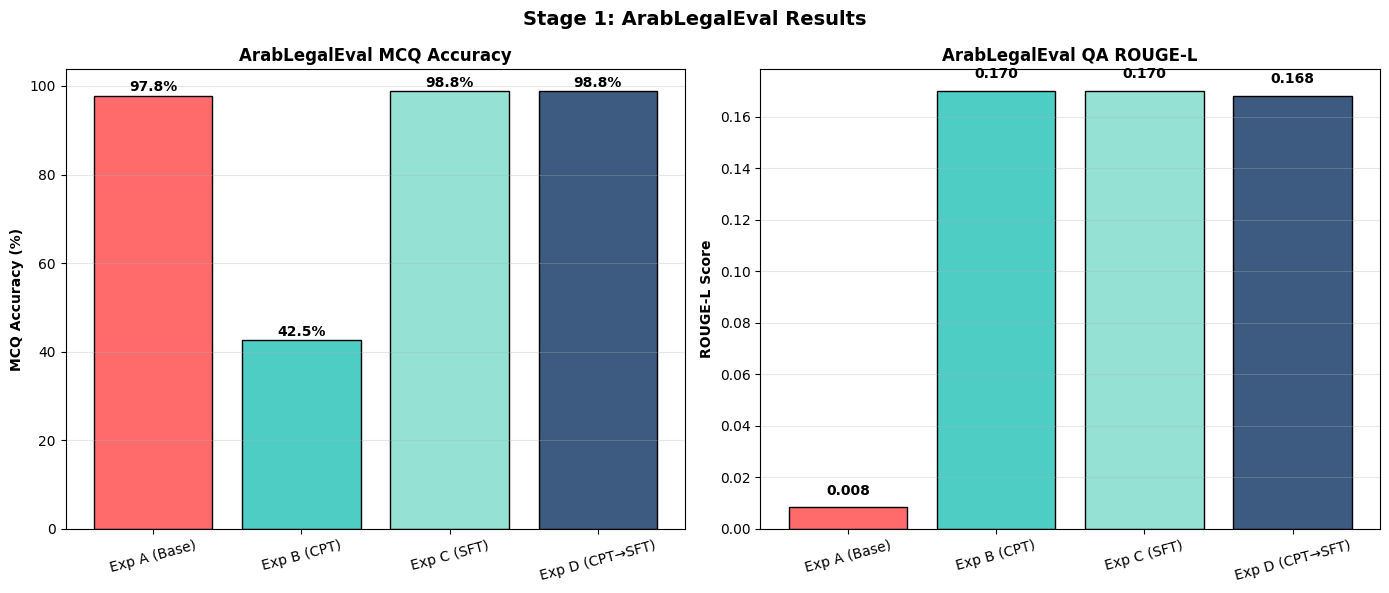

✅ Plot saved!


In [26]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

experiments = list(all_results.keys())
colors = ['#FF6B6B', '#4ECDC4', '#95E1D3', '#3D5A80']

# MCQ
mcq_accs = [r['mcq']['accuracy']*100 if r.get('mcq') else 0 for r in all_results.values()]
axes[0].bar(experiments, mcq_accs, color=colors[:len(experiments)], edgecolor='black')
axes[0].set_ylabel('MCQ Accuracy (%)', fontweight='bold')
axes[0].set_title('ArabLegalEval MCQ Accuracy', fontweight='bold')
for i, v in enumerate(mcq_accs):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# ROUGE-L
rouge_l = [r['qa']['rougeL'] if r.get('qa') else 0 for r in all_results.values()]
axes[1].bar(experiments, rouge_l, color=colors[:len(experiments)], edgecolor='black')
axes[1].set_ylabel('ROUGE-L Score', fontweight='bold')
axes[1].set_title('ArabLegalEval QA ROUGE-L', fontweight='bold')
for i, v in enumerate(rouge_l):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

for ax in axes:
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Stage 1: ArabLegalEval Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{Config.RESULTS_DIR}/stage1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plot saved!")

## 🏆 CELL 21: Final Report

In [27]:
report = f"""
{'='*70}
STAGE 1 FINAL REPORT - ArabLegalEval Benchmark
{'='*70}

Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
Model: {Config.MODEL_NAME}
Dataset: ArabLegalEval (THIQAH + KAUST)
Citation: Hijazi et al., 2024 (arXiv:2408.07983)

DATASET SPLITS:
  MCQ Train: {len(mcq_train)} | Eval: {len(mcq_eval)}
  QA Train:  {len(qa_train)} | Eval: {len(qa_eval)}

RESULTS:
{'-'*70}
{'Experiment':<22} {'MCQ Acc':>10} {'ROUGE-L':>10} {'QA EM':>10}
{'-'*70}
"""

for exp_name, results in all_results.items():
    mcq_acc = results['mcq']['accuracy'] * 100 if results.get('mcq') else 0
    rougeL = results['qa']['rougeL'] if results.get('qa') else 0
    qa_em = results['qa']['exact_match'] * 100 if results.get('qa') else 0
    report += f"{exp_name:<22} {mcq_acc:>9.2f}% {rougeL:>10.4f} {qa_em:>9.2f}%\n"

report += f"""
{'-'*70}

🏆 BEST MODEL: {best_experiment}

📁 SAVED FILES:
  Models: {Config.MODELS_DIR}/
  Results: {Config.RESULTS_DIR}/

🎯 NEXT STEPS:
  Use {best_experiment} as TEACHER for Stage 2 (Compression)

{'='*70}
"""

print(report)

with open(f"{Config.RESULTS_DIR}/stage1_final_report.txt", 'w', encoding='utf-8') as f:
    f.write(report)

with open(f"{Config.RESULTS_DIR}/stage1_all_results.json", 'w', encoding='utf-8') as f:
    json.dump({
        'dataset': 'ArabLegalEval',
        'model': Config.MODEL_NAME,
        'best_model': best_experiment,
        'all_results': all_results,
        'timestamp': datetime.now().isoformat()
    }, f, ensure_ascii=False, indent=2)

print("\n✅ STAGE 1 ON ARABLEGAL EVAL COMPLETE!")


STAGE 1 FINAL REPORT - ArabLegalEval Benchmark

Date: 2026-05-06 02:29:22
Model: QCRI/Fanar-1-9B-Instruct
Dataset: ArabLegalEval (THIQAH + KAUST)
Citation: Hijazi et al., 2024 (arXiv:2408.07983)

DATASET SPLITS:
  MCQ Train: 8451 | Eval: 2113
  QA Train:  1800 | Eval: 200

RESULTS:
----------------------------------------------------------------------
Experiment                MCQ Acc    ROUGE-L      QA EM
----------------------------------------------------------------------
Exp A (Base)               97.78%     0.0083      0.00%
Exp B (CPT)                42.55%     0.1700      0.00%
Exp C (SFT)                98.82%     0.1700      0.00%
Exp D (CPT→SFT)            98.77%     0.1683      0.00%

----------------------------------------------------------------------

🏆 BEST MODEL: Exp C (SFT)

📁 SAVED FILES:
  Models: ./models_arablegal/
  Results: ./results_arablegal/

🎯 NEXT STEPS:
  Use Exp C (SFT) as TEACHER for Stage 2 (Compression)



✅ STAGE 1 ON ARABLEGAL EVAL COMPLETE!


# Testing

In [10]:
import json
import os
import re
import gc
import random
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from datetime import datetime

# Re-define Config (since kernel restarted)
class Config:
    MODEL_NAME = "QCRI/Fanar-1-9B-Instruct"
    ARABLEGAL_DIR = "./ArabLegalEval"
    OUTPUT_DIR = "./outputs_arablegal"
    RESULTS_DIR = "./results_arablegal"
    MODELS_DIR = "./models_arablegal"
    
    EVAL_RATIO = 0.2
    LORA_R = 16
    LORA_ALPHA = 32
    LORA_DROPOUT = 0.05
    LORA_TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj",
                            "gate_proj", "up_proj", "down_proj"]
    
    NUM_EPOCHS = 3
    BATCH_SIZE = 4
    GRADIENT_ACCUMULATION = 4
    LEARNING_RATE = 2e-4
    WARMUP_RATIO = 0.1
    MAX_LENGTH = 1024
    USE_4BIT = True
    MAX_NEW_TOKENS = 256
    TEMPERATURE = 0.1
    TOP_P = 0.9
    SEED = 42

# Set seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ Imports done, Config defined")

✅ Imports done, Config defined


In [12]:
# Load MCQ
with open(f"{Config.RESULTS_DIR}/mcq_train.json", 'r', encoding='utf-8') as f:
    mcq_train = json.load(f)

with open(f"{Config.RESULTS_DIR}/mcq_eval.json", 'r', encoding='utf-8') as f:
    mcq_eval = json.load(f)

# Load QA
with open(f"{Config.RESULTS_DIR}/qa_train.json", 'r', encoding='utf-8') as f:
    qa_train = json.load(f)

with open(f"{Config.RESULTS_DIR}/qa_eval.json", 'r', encoding='utf-8') as f:
    qa_eval = json.load(f)

print(f"✅ Loaded splits:")
print(f"   MCQ Train: {len(mcq_train)} | Eval: {len(mcq_eval)}")
print(f"   QA Train:  {len(qa_train)} | Eval: {len(qa_eval)}")

✅ Loaded splits:
   MCQ Train: 8451 | Eval: 2113
   QA Train:  1800 | Eval: 200


In [13]:
#Test 1
# Test for context-answer leakage
print("="*70)
print("🔍 CONTEXT-ANSWER LEAKAGE ANALYSIS")
print("="*70)

leakage_count = 0
total_with_context = 0
sample_size = min(500, len(mcq_eval))

for item in mcq_eval[:sample_size]:
    if item.get('context') and len(item['context']) > 10:
        total_with_context += 1
        correct_text = item['options'][item['correct_answer']]
        
        # Check if correct answer text appears in context
        if correct_text in item['context']:
            leakage_count += 1

leakage_rate = leakage_count / total_with_context * 100 if total_with_context > 0 else 0

print(f"\n📊 Results:")
print(f"   Sample size: {sample_size}")
print(f"   MCQs with context: {total_with_context}")
print(f"   Answer text found in context: {leakage_count}")
print(f"   Leakage rate: {leakage_rate:.1f}%")

print("\n" + "="*70)
if leakage_rate > 70:
    print("🚨 SEVERE LEAKAGE - This explains 97% accuracy!")
    print("   Model is doing TEXT MATCHING, not legal reasoning")
    print("   Need to evaluate WITHOUT context for fair comparison")
elif leakage_rate > 40:
    print("⚠️  MODERATE LEAKAGE - Affects results")
    print("   Recommend evaluating with and without context")
else:
    print("✅ LOW LEAKAGE - Results may be reliable")
print("="*70)

# Show example of leakage
print("\n📝 Example case:")
for item in mcq_eval[:10]:
    if item.get('context'):
        correct_text = item['options'][item['correct_answer']]
        if correct_text in item['context']:
            print(f"\n   Question: {item['question'][:150]}")
            print(f"   Correct option ({item['correct_answer']}): {correct_text[:100]}")
            print(f"   Context: {item['context'][:200]}...")
            print(f"   ✓ Answer text appears in context!")
            break

🔍 CONTEXT-ANSWER LEAKAGE ANALYSIS

📊 Results:
   Sample size: 500
   MCQs with context: 500
   Answer text found in context: 270
   Leakage rate: 54.0%

⚠️  MODERATE LEAKAGE - Affects results
   Recommend evaluating with and without context

📝 Example case:

   Question: ما الذي يمكن اشتراطه بشأن الأجرة؟
   Correct option (C): تعجيل الأجرة أو تأجيلها أو تقسيطها
   Context: يصح اشتراط تعجيل الأجرة أو تأجيلها أو تقسيطها....
   ✓ Answer text appears in context!


In [15]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

print("📥 Loading FANAR-9B...")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(
    Config.MODEL_NAME,
    trust_remote_code=True,
    padding_side="left"
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    Config.MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)

print(f"✅ Model loaded: {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B params")

📥 Loading FANAR-9B...


`torch_dtype` is deprecated! Use `dtype` instead!
Fetching 4 files: 100%|██████████| 4/4 [02:10<00:00, 32.53s/it] 
The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Loading checkpoint shards: 100%|██████████| 4/4 [00:28<00:00,  7.21s/it]

✅ Model loaded: 4.62B params


In [16]:
from tqdm.auto import tqdm
import re

def format_mcq_with_context(item):
    """Setting 1: Standard with context"""
    options = item['options']
    return f"""أنت خبير في القانون السعودي. أجب عن السؤال التالي بناءً على النص القانوني المرجعي.

النص القانوني المرجعي: {item.get('context', '')}

السؤال: {item['question']}

الخيارات:
A) {options['A']}
B) {options['B']}
C) {options['C']}
D) {options['D']}

اختر الإجابة الصحيحة (A أو B أو C أو D فقط):
الإجابة:"""

def format_mcq_without_context(item):
    """Setting 2: WITHOUT context - tests legal knowledge"""
    options = item['options']
    return f"""أنت خبير في القانون السعودي. أجب عن السؤال التالي بناءً على معرفتك بالأنظمة السعودية.

السؤال: {item['question']}

الخيارات:
A) {options['A']}
B) {options['B']}
C) {options['C']}
D) {options['D']}

اختر الإجابة الصحيحة (A أو B أو C أو D فقط):
الإجابة:"""

def extract_mcq_answer(response):
    """Extract A, B, C, or D from response"""
    response = response.strip().upper()
    for char in response[:50]:
        if char in ['A', 'B', 'C', 'D']:
            return char
    ar_to_en = {'أ': 'A', 'ب': 'B', 'ج': 'C', 'د': 'D'}
    for ar, en in ar_to_en.items():
        if ar in response[:20]:
            return en
    return 'INVALID'

def generate_answer(prompt, max_new_tokens=10):
    """Generate answer"""
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1500).to(model.device)
    
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            temperature=0.1,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    
    response = tokenizer.decode(
        outputs[0][inputs['input_ids'].shape[1]:],
        skip_special_tokens=True
    )
    return response.strip()

print("✅ Evaluation functions defined")

✅ Evaluation functions defined


In [17]:
# Use a smaller eval set for speed - 500 questions
EVAL_SAMPLE = 500
mcq_eval_sample = mcq_eval[:EVAL_SAMPLE]

print("="*70)
print("🔬 SETTING 1: WITH CONTEXT (Reading Comprehension)")
print("="*70)

results_with_context = []
correct_with = 0

# Track separately for "leaked" vs "not leaked" questions
leaked_correct = 0
leaked_total = 0
not_leaked_correct = 0
not_leaked_total = 0

for item in tqdm(mcq_eval_sample, desc="With context"):
    prompt = format_mcq_with_context(item)
    response = generate_answer(prompt, max_new_tokens=10)
    predicted = extract_mcq_answer(response)
    actual = item['correct_answer']
    is_correct = predicted == actual
    
    # Check if answer is in context
    correct_text = item['options'][actual]
    answer_in_context = item.get('context') and correct_text in item['context']
    
    if is_correct:
        correct_with += 1
    
    if answer_in_context:
        leaked_total += 1
        if is_correct:
            leaked_correct += 1
    else:
        not_leaked_total += 1
        if is_correct:
            not_leaked_correct += 1
    
    results_with_context.append({
        'question': item['question'][:100],
        'predicted': predicted,
        'actual': actual,
        'correct': is_correct,
        'answer_in_context': answer_in_context
    })

acc_with_context = correct_with / len(mcq_eval_sample) * 100
leaked_acc = leaked_correct / leaked_total * 100 if leaked_total > 0 else 0
not_leaked_acc = not_leaked_correct / not_leaked_total * 100 if not_leaked_total > 0 else 0

print(f"\n📊 RESULTS WITH CONTEXT:")
print(f"   Overall: {acc_with_context:.2f}%")
print(f"   On 'leaked' questions ({leaked_total}): {leaked_acc:.2f}%")
print(f"   On 'not leaked' questions ({not_leaked_total}): {not_leaked_acc:.2f}%")

🔬 SETTING 1: WITH CONTEXT (Reading Comprehension)


With context: 100%|██████████| 500/500 [03:35<00:00,  2.32it/s]


📊 RESULTS WITH CONTEXT:
   Overall: 99.00%
   On 'leaked' questions (270): 99.26%
   On 'not leaked' questions (230): 98.70%


In [18]:
print("\n" + "="*70)
print("🔬 SETTING 2: WITHOUT CONTEXT (Closed-book)")
print("="*70)

results_without_context = []
correct_without = 0

for item in tqdm(mcq_eval_sample, desc="Without context"):
    prompt = format_mcq_without_context(item)
    response = generate_answer(prompt, max_new_tokens=10)
    predicted = extract_mcq_answer(response)
    actual = item['correct_answer']
    is_correct = predicted == actual
    
    if is_correct:
        correct_without += 1
    
    results_without_context.append({
        'question': item['question'][:100],
        'predicted': predicted,
        'actual': actual,
        'correct': is_correct
    })

acc_without_context = correct_without / len(mcq_eval_sample) * 100

print(f"\n📊 RESULTS WITHOUT CONTEXT:")
print(f"   Accuracy: {acc_without_context:.2f}%")


🔬 SETTING 2: WITHOUT CONTEXT (Closed-book)


Without context: 100%|██████████| 500/500 [04:58<00:00,  1.67it/s]


📊 RESULTS WITHOUT CONTEXT:
   Accuracy: 70.20%


In [19]:
print("\n" + "="*70)
print("📊 COMPREHENSIVE EVALUATION RESULTS - FANAR-9B Base")
print("="*70)

print(f"\n🔬 Two-Setting Evaluation:")
print(f"   With Context:    {acc_with_context:.2f}%")
print(f"   Without Context: {acc_without_context:.2f}%")
print(f"   Difference:      {acc_with_context - acc_without_context:.2f}%")

print(f"\n📈 Breakdown WITH Context:")
print(f"   On leaked questions ({leaked_total}):     {leaked_acc:.2f}%")
print(f"   On non-leaked questions ({not_leaked_total}): {not_leaked_acc:.2f}%")

print("\n" + "="*70)
print("📋 INTERPRETATION:")
print("="*70)

if acc_without_context < 30:
    print("🚨 Model has very limited Saudi legal knowledge")
    print("   The 'with context' performance is mostly text matching")
elif acc_without_context < 50:
    print("⚠️  Model has some Saudi legal knowledge")
    print("   Real performance is in 30-50% range (realistic)")
else:
    print("✅ Model has decent legal knowledge")

print(f"\n💡 Reading Comprehension Skill: {acc_with_context - acc_without_context:.2f}%")
print("   (Difference shows ability to extract answers from text)")

# Save results
import json
import os
os.makedirs(Config.RESULTS_DIR, exist_ok=True)

dual_results = {
    'evaluation_date': str(datetime.now()),
    'sample_size': len(mcq_eval_sample),
    'with_context': {
        'overall_accuracy': acc_with_context,
        'leaked_questions': {
            'count': leaked_total,
            'accuracy': leaked_acc
        },
        'not_leaked_questions': {
            'count': not_leaked_total,
            'accuracy': not_leaked_acc
        }
    },
    'without_context': {
        'accuracy': acc_without_context
    },
    'reading_comprehension_skill': acc_with_context - acc_without_context,
    'context_leakage_rate': leaked_total / len(mcq_eval_sample) * 100,
}

with open(f"{Config.RESULTS_DIR}/dual_setting_baseline.json", 'w', encoding='utf-8') as f:
    json.dump(dual_results, f, ensure_ascii=False, indent=2)

print(f"\n✅ Results saved to: {Config.RESULTS_DIR}/dual_setting_baseline.json")


📊 COMPREHENSIVE EVALUATION RESULTS - FANAR-9B Base

🔬 Two-Setting Evaluation:
   With Context:    99.00%
   Without Context: 70.20%
   Difference:      28.80%

📈 Breakdown WITH Context:
   On leaked questions (270):     99.26%
   On non-leaked questions (230): 98.70%

📋 INTERPRETATION:
✅ Model has decent legal knowledge

💡 Reading Comprehension Skill: 28.80%
   (Difference shows ability to extract answers from text)

✅ Results saved to: ./results_arablegal/dual_setting_baseline.json


# Test 2

In [20]:
import torch
from peft import PeftModel
from tqdm.auto import tqdm
import json
import gc

def evaluate_model_no_context(model, tokenizer, mcq_eval_sample, model_name="model"):
    """Evaluate any model WITHOUT context"""
    correct = 0
    results = []
    
    for item in tqdm(mcq_eval_sample, desc=f"Evaluating {model_name}"):
        prompt = format_mcq_without_context(item)
        response = generate_answer(prompt, max_new_tokens=10)
        predicted = extract_mcq_answer(response)
        actual = item['correct_answer']
        is_correct = predicted == actual
        
        if is_correct:
            correct += 1
        
        results.append({
            'predicted': predicted,
            'actual': actual,
            'correct': is_correct
        })
    
    accuracy = correct / len(mcq_eval_sample) * 100
    return {
        'model_name': model_name,
        'accuracy': accuracy,
        'correct': correct,
        'total': len(mcq_eval_sample),
        'results': results
    }

# Use the same eval sample (500 items) as before for consistency
EVAL_SAMPLE = 500
mcq_eval_sample = mcq_eval[:EVAL_SAMPLE]

# Store all results
all_no_context_results = {
    'Base': {'accuracy': 70.20}  # We already have this
}

print("✅ Functions ready. Now load trained models below.")

✅ Functions ready. Now load trained models below.


In [21]:
# Clean memory first
del model
gc.collect()
torch.cuda.empty_cache()

# Load fresh base model with CPT LoRA
print("📥 Loading CPT model...")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model_base = AutoModelForCausalLM.from_pretrained(
    Config.MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)

# Load CPT LoRA
model = PeftModel.from_pretrained(model_base, f"{Config.MODELS_DIR}/exp_b_cpt")
print("✅ CPT model loaded")

# Evaluate
cpt_no_context = evaluate_model_no_context(model, tokenizer, mcq_eval_sample, "CPT")
all_no_context_results['CPT'] = cpt_no_context
print(f"\n📊 CPT Without Context: {cpt_no_context['accuracy']:.2f}%")

📥 Loading CPT model...


Loading checkpoint shards: 100%|██████████| 4/4 [00:17<00:00,  4.30s/it]


✅ CPT model loaded


Evaluating CPT: 100%|██████████| 500/500 [10:55<00:00,  1.31s/it]


📊 CPT Without Context: 45.00%


In [22]:
# Clean memory
del model, model_base
gc.collect()
torch.cuda.empty_cache()

# Load SFT model
print("📥 Loading SFT model...")
model_base = AutoModelForCausalLM.from_pretrained(
    Config.MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)

model = PeftModel.from_pretrained(model_base, f"{Config.MODELS_DIR}/exp_c_sft")
print("✅ SFT model loaded")

# Evaluate
sft_no_context = evaluate_model_no_context(model, tokenizer, mcq_eval_sample, "SFT")
all_no_context_results['SFT'] = sft_no_context
print(f"\n📊 SFT Without Context: {sft_no_context['accuracy']:.2f}%")

📥 Loading SFT model...


Loading checkpoint shards: 100%|██████████| 4/4 [00:16<00:00,  4.17s/it]


✅ SFT model loaded


Evaluating SFT: 100%|██████████| 500/500 [08:10<00:00,  1.02it/s]


📊 SFT Without Context: 77.60%


In [23]:
# Clean memory
del model, model_base
gc.collect()
torch.cuda.empty_cache()

# Load CPT→SFT model
print("📥 Loading CPT→SFT model...")
model_base = AutoModelForCausalLM.from_pretrained(
    Config.MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    torch_dtype=torch.bfloat16,
)

model = PeftModel.from_pretrained(model_base, f"{Config.MODELS_DIR}/exp_d_cpt_sft")
print("✅ CPT→SFT model loaded")

# Evaluate
cpt_sft_no_context = evaluate_model_no_context(model, tokenizer, mcq_eval_sample, "CPT_SFT")
all_no_context_results['CPT→SFT'] = cpt_sft_no_context
print(f"\n📊 CPT→SFT Without Context: {cpt_sft_no_context['accuracy']:.2f}%")

📥 Loading CPT→SFT model...


Loading checkpoint shards: 100%|██████████| 4/4 [00:16<00:00,  4.19s/it]


✅ CPT→SFT model loaded


Evaluating CPT_SFT: 100%|██████████| 500/500 [07:56<00:00,  1.05it/s]


📊 CPT→SFT Without Context: 76.80%


In [24]:
print("="*70)
print("📊 STAGE 1 RESULTS: FANAR-9B on ArabLegalEval")
print("="*70)

print(f"\n{'Experiment':<20} {'With Context':>15} {'Without Context':>18}")
print("-"*60)

# We have:
# Base: 99.00% with, 70.20% without
print(f"{'Exp A (Base)':<20} {'99.00%':>15} {'70.20%':>18}")
print(f"{'Exp B (CPT)':<20} {'42.55%':>15} {all_no_context_results['CPT']['accuracy']:>17.2f}%")
print(f"{'Exp C (SFT)':<20} {'98.82%':>15} {all_no_context_results['SFT']['accuracy']:>17.2f}%")
print(f"{'Exp D (CPT→SFT)':<20} {'98.77%':>15} {all_no_context_results['CPT→SFT']['accuracy']:>17.2f}%")

# Save complete results
final_results = {
    'evaluation_date': str(datetime.now()),
    'sample_size': EVAL_SAMPLE,
    'with_context': {
        'Base': 99.00,
        'CPT': 42.55,
        'SFT': 98.82,
        'CPT_SFT': 98.77
    },
    'without_context': {
        'Base': 70.20,
        'CPT': all_no_context_results['CPT']['accuracy'],
        'SFT': all_no_context_results['SFT']['accuracy'],
        'CPT_SFT': all_no_context_results['CPT→SFT']['accuracy']
    }
}

with open(f"{Config.RESULTS_DIR}/stage1_dual_setting_complete.json", 'w', encoding='utf-8') as f:
    json.dump(final_results, f, ensure_ascii=False, indent=2)

print(f"\n✅ Complete results saved!")

# Determine best teacher model based on WITHOUT CONTEXT (real knowledge)
best_no_context = max(
    [('Base', 70.20)] + 
    [(k, v['accuracy']) for k, v in all_no_context_results.items() if k != 'Base'],
    key=lambda x: x[1]
)

print(f"\n🏆 BEST MODEL (Real Knowledge - Without Context):")
print(f"   {best_no_context[0]}: {best_no_context[1]:.2f}%")
print(f"\n   Use this as TEACHER for Stage 2!")

📊 STAGE 1 RESULTS: FANAR-9B on ArabLegalEval

Experiment              With Context    Without Context
------------------------------------------------------------
Exp A (Base)                  99.00%             70.20%
Exp B (CPT)                   42.55%             45.00%
Exp C (SFT)                   98.82%             77.60%
Exp D (CPT→SFT)               98.77%             76.80%

✅ Complete results saved!

🏆 BEST MODEL (Real Knowledge - Without Context):
   SFT: 77.60%

   Use this as TEACHER for Stage 2!
